# GET-Pak workflow tutorial to process water quality parameters (L2B) from a single Sentinel-2 L2A image

This tutorial shows the processing steps for processing a single Sentinel-2 image atmospherically-corrected using [GRS](https://grs.readthedocs.io/en/latest/), with a water mask produced using [WaterDetect](https://github.com/cordmaur/WaterDetect). It is meant to explain every step of the image processing scheme in a more detailed manner. For a jupyter notebook for multiple image processing, explaining it with a parallel with the automated pipeline processing, see file `l2b_workflow.ipynb`.<br> The image used as example here was taken on 7 September 2023 from tile 31TCJ (France) and are available from the Github repository (same folder as this tutorial).

## Summary

[1. Resolve the repository path](#1.-Resolve-the-repository-path)  
[2. Import GET-Pak functions](#2.-Import-GET-Pak-functions)  
[3. Specify folder paths](#3.-Specify-folder-paths)  
[4. Accessing GRS image](#4.-Accessing-GRS-image)  
[5. Intersecting with water mask](#5.-Intersecting-with-water-mask)  
[6. Filter bad pixels](#6.-Filter-bad-pixels)  
[7. Classify OWTs](#7.-Classify-OWTs)  
[8. Calculate water quality parameters](#8.-Calculate-water-quality-parameters)  
[9. Write GeoTIFF outputs](#9.-Write-GeoTIFF-outputs)  
[10. Close open datasets](#10.-Close-open-datasets)  

## 1. Resolve the repository path

First, to import the `getpak` functions (specially for Windows user), the installation path must be especified to be used.

In [1]:
import os
import sys
import json
import math
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path

import rasterio # for visualisation purposes only

In [2]:
Path.cwd()

PosixPath('/home/matheus/Documents/git_projects/get-pak/examples')

In [ ]:
# Path to your GET-Pak folder
REPO_ROOT = Path('~/get-pak')

#### Checking if the directory is correct

In [4]:
if not (REPO_ROOT / "getpak").exists():
    REPO_ROOT = REPO_ROOT.parent

if not (REPO_ROOT / "getpak").exists():
    raise RuntimeError("Could not find the GET-Pak repository root.")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

REPO_ROOT
print(f"GET-Pak path OK : {REPO_ROOT}")

GET-Pak path OK : /home/matheus/Documents/git_projects/get-pak


## 2. Import GET-Pak functions

In [5]:
from getpak.input import Input, GRS, get_input_nc
from getpak.methods import Methods
from getpak.output import Raster
from getpak.commons import Utils

input_reader = Input()
grs_reader = GRS()
methods = Methods()
output = Raster()

Utils.print_logo()


            _..._
          .'     '.      _
         /    .-""-\   _/ \ 
       .-|   /:.   |  |   | 
       |  \  |:.   /.-'-./ 
       | .-'-;:__.'    =/  ,ad8888ba,  88888888888 888888888888                          88
       .'=  *=|CNES _.='  d8"'    `"8b 88               88                               88
      /   _.  |    ;     d8'           88               88                               88
     ;-.-'|    \   |     88            88aaaaa          88        8b,dPPYba,  ,adPPYYba, 88   ,d8
    /   | \    _\  _\    88      88888 88"""""          88 aaaaaa 88P'    "8a ""     `Y8 88 ,a8"
    \__/'._;.  ==' ==\   Y8,        88 88               88 """""" 88       d8 ,adPPPPP88 8888[
    /|\  /|\ \    \   |   Y8a.    .a88 88               88        88b,   ,a8" 88,    ,88 88`"Yba,
   / | \/ | \/    /   /    `"Y88888P"  88888888888      88        88`YbbdP"'  `"8bbdP"Y8 88   `Y8a
  /  | || |  /-._/-._/                                            88
             \   `\  \              

## 3. Specify folder paths

Setting the folder paths for the GRS image, WaterDetect masks, and output folder:

In [ ]:
l2a_path = "~/get-pak/examples/GRS/S2B_MSIL2AGRS_20230907T104629_N0510_R051_T31TCJ_20241026T031220_V2.1.9.nc"
wmask_path = "~/get-pak/examples/WaterDetect/SENTINEL2B_20230907-105903-095_L2A_T31TCJ_C_V3-1_water_mask.tif"
output_folder = "~/get-pak/examples/Outputs"

print(f"GRS input: {l2a_path}")
print(f"Water mask: {wmask_path}")
print(f"Output folder: {output_folder}\n")

# metadata
meta = GRS().metadata(l2a_path)

print(f"Sentinel-2 tile: {meta['tile']}")
print(f"Image date: {meta['str_date']}")
print(f"GRS version: {meta['grs_ver']}")

GRS input: /home/matheus/Documents/git_projects/get-pak/examples/GRS/S2B_MSIL2AGRS_20230907T104629_N0510_R051_T31TCJ_20241026T031220_V2.1.9.nc
Water mask: /home/matheus/Documents/git_projects/get-pak/examples/WaterDetect/SENTINEL2B_20230907-105903-095_L2A_T31TCJ_C_V3-1_water_mask.tif
Output folder: /home/matheus/Documents/git_projects/get-pak/examples/Outputs

Sentinel-2 tile: T31TCJ
Image date: 20230907
GRS version: V2.1.9


## 4. Accessing GRS image

Let's open the GRS image and visualize some features. To open the GRS image, we use the function `get_input_nc` from the class Input (imported as `input_reader`):

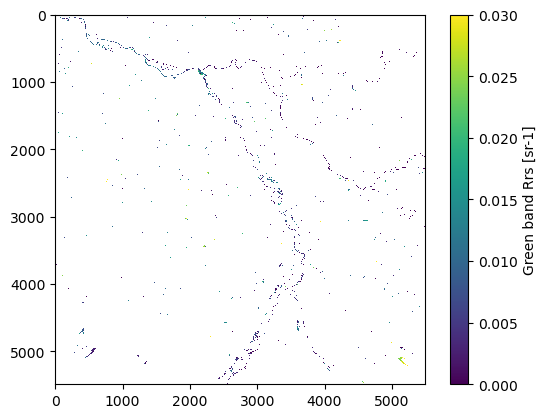

In [7]:
# Opening L2A image. The GRS version for this image is 2.1.9 (thus using option v21 for `grs_version`)
grs_t = input_reader.get_input_nc(file=l2a_path, sensor='S2MSI', AC_processor='GRS', grs_version='v21')

# plot
plt.imshow(grs_t['Red'], cmap="viridis", vmin=0, vmax=0.03, interpolation='nearest')
plt.colorbar(label="Green band Rrs [sr-1]")
plt.show()

## 5. Intersecting with water mask

Intersecting the GRS image with the water mask produced using WaterDetect.

First we'll open the water mask only to visualise it; for processing purposes it is not necessary to open it explicitly.

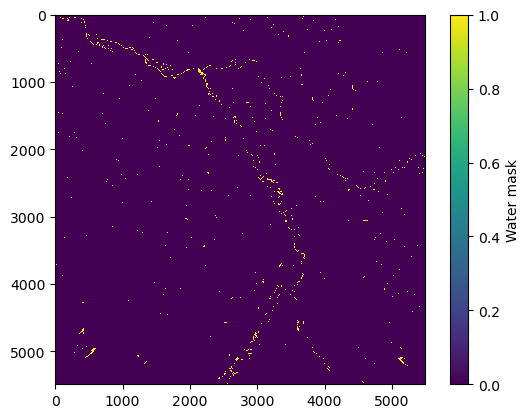

In [8]:
# Opening the water mask to visualise it
with rasterio.open(
            fp=Path(wmask_path),
            mode='r',
            driver='GTiff',
            dtype='uint8',
            crs=grs_t.attrs['proj'],
            transform=grs_t.attrs['trans'],
            nodata=0,
        ) as file:
            plt.imshow(file.read(1), interpolation='nearest')
            plt.colorbar(label="Water mask")
            plt.show()

Now let's finally intersect the GRS image data with the water mask, so that we only have reflectance over water pixels.

In [9]:
grs = methods.intersect_watermask(rrs_dict=grs_t, water_mask_dir=wmask_path)

Done.


## 6. Filter bad pixels

This function uses an automated processing to remove what is considered as bad pixels from the processing. By bad pixels we consider those that are either produced by artefacts such as adjacency effects or over-correction of the atmospheric effects by the atmospheric correction algorithm.</br> For this we consider there filters: negative Rrs, which is physically impossible; very low reflectance, which is not impossible but causes unreliable values generated by the inversion algorithms; a removed of vegetation-like water pixels, which we consider a cause of adjacency effects.</br> For the negative Rrs, we recommend using the `Red` band, as it is generally lower than the blue and green bands for water, but not as low as for for the infrared bands (and thus more restrictive).</br> For the very low Rrs, we consider the maximum Rrs from bands 1 to 6 as these are usually less affected by adjacency effects, and we use a threshold of 0.002 which was considered the limit where most inversion models could work well in our tests (Tavares et al., 2025).</br> The explanation of the removal of vegetation-like water pixels is further explained below.</br> In order to visualise the effect of this filtering, the number of pixels removed is saved on a file named `npixels_*.txt`.

In [10]:
pixels = np.array([
    ["Water_pixels", "0"],
    ["Neg_Rrs_B4", "0"],
    ["Low_Rrs", "0"],
    ["OWT_1", "0"],
], dtype=object)

low_rrs_bands = ["Aerosol", "Blue", "Green", "Red", "RedEdge1", "RedEdge2"]

grs = methods.filter_pixels(
    rrs_dict=grs,
    neg_rrs="Red",
    low_rrs=True,
    low_rrs_thresh=0.002,
    low_rrs_bands=low_rrs_bands,
)

pixels[0, 1] = methods.npix
pixels[1, 1] = methods.negpix
pixels[2, 1] = methods.lowrrs

pixels
print(f"Total water pixels in the image: {pixels[0,1]}")
print(f"Negative B4 pixels removed: {pixels[1,1]}")
print(f"Low Rrs pixels removed: {pixels[2,1]}")

Total water pixels in the image: 186564
Negative B4 pixels removed: 6616
Low Rrs pixels removed: 15


## 7. Classify OWTs

To automate the selection of the invertion algorithms for estimating chlorophyll-a (`chla`) and `turbidity`, we use a classification method name Optical Water Types (`OWTs`), which classifies the water quality status of each water pixel based on its spectral signature. We use two separate `OWT` schemes, a normalised method with 13 classes for chla (Spyrakos et al., 2018), and a regular Rrs scheme with 4 classes for turbidity (Cordeiro, 2022).</br> The pixels classified as OWT1 on the Spyrakos scheme have vegetation-like spectral signature, as considered as artefacts due to adjacency effects, and are filtered out from the image.

In [11]:
class_px, angles = methods.classify_owt_chla_px(rrs_dict=grs, sensor="S2MSI", B1=True)

if class_px.sum() <= 0:
    raise RuntimeError("No valid pixels were found for this image after filtering.")

# calculating chla weights for the blended chla product
owt_classes, owt_weights = methods.classify_owt_chla_weights(class_px=class_px, angles=angles, n=3)

pixels[3, 1] = np.count_nonzero(owt_classes[0, :, :] == 1)

class_turb, angles_turb = methods.classify_owt_spm_px(rrs_dict=grs, sensor="S2MSI", B1=True)

# calculating turbidity weights for the blended turbidity product
owt_turb_classes, owt_turb_weights = methods.classify_owt_spm_weights(class_px=class_turb, angles=angles_turb, n=2)

print(f"OWT-1 pixels removed: {pixels[3,1]}")
print(pixels)

OWT-1 pixels removed: 45967
[['Water_pixels' 186564]
 ['Neg_Rrs_B4' 6616]
 ['Low_Rrs' 15]
 ['OWT_1' 45967]]


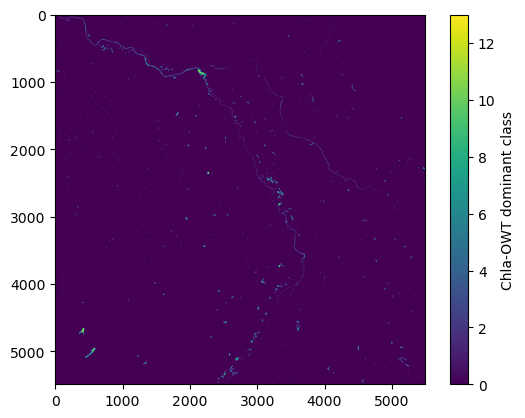

In [12]:
# plot of chla OWT classes
plt.imshow(owt_classes[0, :, :], cmap="viridis")
plt.colorbar(label="Chla-OWT dominant class")
plt.show()

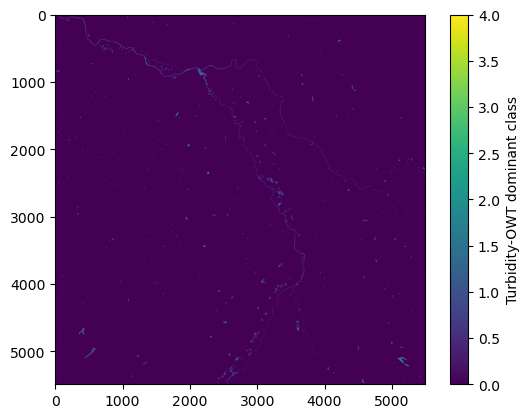

In [13]:
# plot of turbidity OWT classes
plt.imshow(class_turb, cmap="viridis")
plt.colorbar(label="Turbidity-OWT dominant class")
plt.show()

A different OWT method to retrieve `chla` is also applied to pixels with low values of `Rrs` but that were not filtered out before. For these pixels, due to their low Rrs, the normalised OWT scheme can classify them as different classes due to artefacts that were not filtered out, causing the wrong retrieval methods to be applied. For these pixels, that in our method we consider a maximum Rrs value of 0.005 sr-1 (still between bands 1 and 6), we stipulate a different class, here numbered as `14`, where we force a chla model adapted to waters with low Rrs (either clear or dark waters).

In [14]:
owt_classes, owt_weights = methods.assign_low_Rrs_OWT(rrs_dict=grs, owt_classes=owt_classes, owt_weights=owt_weights, rrs_thresh=0.005, low_rrs_bands=low_rrs_bands)

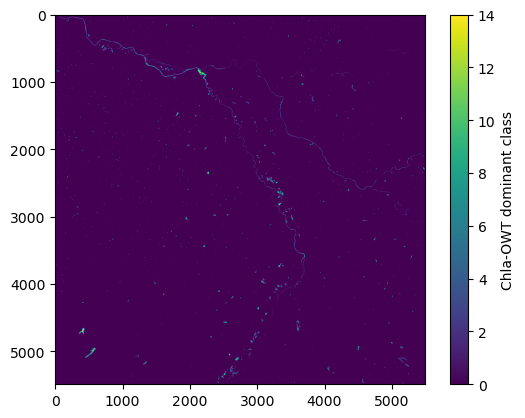

In [15]:
# plot of updated chla OWTs
plt.imshow(owt_classes[0, :, :], cmap="viridis")
plt.colorbar(label="Chla-OWT dominant class")
plt.show()

## 8. Calculate water quality parameters

Here we use the functions that will apply specific inversion models for the different chla and turbidity class, and create a blended product for each. As calculated before, for this blended product we use the 3 dominant classes for chla and the 2 dominant classes for turbidity:

In [ ]:
chla = methods.blended_chla(rrs_dict=grs, owt_classes=owt_classes, owt_weights=owt_weights, limits=True)

turb = methods.blended_turb(rrs_dict=grs, owt_classes=owt_turb_classes, owt_weights=owt_turb_weights, limits=True)

# making sure that for OWT1, there is no data
chla[np.where(owt_classes[0, :, :] == 1)] = 0
turb[np.where(owt_classes[0, :, :] == 1)] = 0

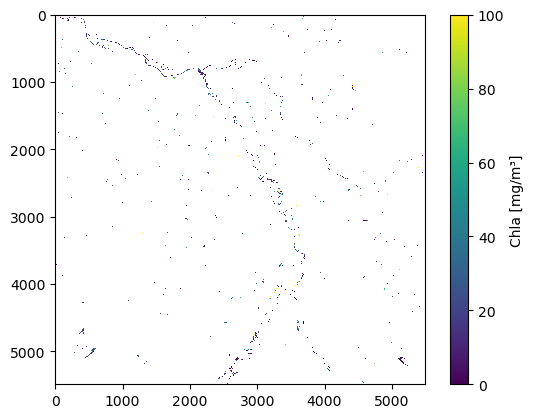

In [17]:
# plot of blended chla values
plt.imshow(chla, cmap="viridis", vmin=0, vmax=100, interpolation='nearest')
plt.colorbar(label="Chla [mg/m³]")
plt.show()

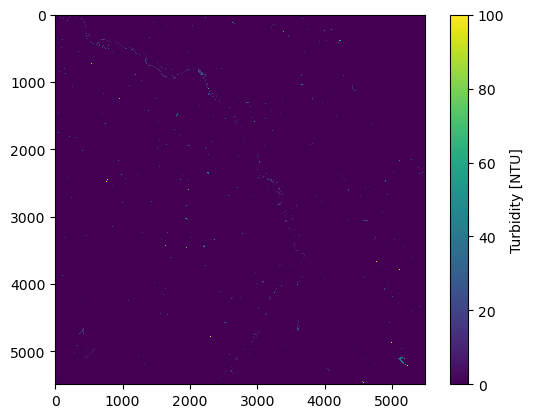

In [18]:
# plot of blended turbidiyy values
plt.imshow(turb, cmap="viridis", vmin=0, vmax=100, interpolation='nearest')
plt.colorbar(label="Turbidity [NTU]")
plt.show()

## 9. Write GeoTIFF outputs

Writing output rasters for each of the parameters produced for this scene over this tutorial.

In order to reduce the size of the output files, we recommend multiplying the products with decimal values (i.e., chla and turbidity) by a large integer value in order to produce integer (int) files, which are considerably lighter. This can make a lot of difference in terms of disk space usage when processing satellite time series.

For this, we recommend multiplying the chla and turbidity products by `100`, to remove the decimal values, and to use a large value (e.g. `999999`) as NoData. This is further explained on the `Raster values and no data` section of the library [github](https://github.com/SNO-HYBAM/get-pak#raster-values-and-no-data) page.

In [19]:
# first writing a text file with the filtered pixels
str_output_file = os.path.join(output_folder, "n_pixels_" + meta['tile'] + meta['str_date'] + ".txt")
np.savetxt(str_output_file, pixels, fmt='%s', delimiter=';')

In [20]:
# writing the OWTs
# using 0 as NoData as there is no OWT 0
no_data = 0
# Name of the output file for chla OWT:
str_output_file = os.path.join(output_folder, "Chla_OWTs_" + meta['tile'] + meta['str_date'] + ".tif")
# Saving as GeoTIFF
output.array2tiff(ndarray_data=owt_classes[0,:,:].astype('uint8'), str_output_file=str_output_file, transform=grs.attrs['trans'], projection=grs.attrs['proj'], no_data=no_data)
# Name of the output file for turbidity OWT:
str_output_file = os.path.join(output_folder, "Turb_OWTs_" + meta['tile'] + meta['str_date'] + ".tif")
# Saving as GeoTIFF
output.array2tiff(ndarray_data=class_turb.astype('uint8'), str_output_file=str_output_file, transform=grs.attrs['trans'], projection=grs.attrs['proj'], no_data=no_data)

print("Successfully written the rasters for the OWTs.")

Successfully written the rasters for the OWTs.


In [52]:
# writing the WQ parameters
# using 0 as NoData
no_data = 0
# treating np.nan as 0
chla[np.where(np.isnan(chla))] = 0
turb[np.where(np.isnan(turb))] = 0
# Name of the output file for chla OWT:
str_output_file = os.path.join(output_folder, "Blended_Chla_" + meta['tile'] + meta['str_date'] + ".tif")
# Saving as GeoTIFF
output.array2tiff(ndarray_data=(chla*100).astype('uint32'), str_output_file=str_output_file, transform=grs.attrs['trans'], projection=grs.attrs['proj'], no_data=no_data)
# Name of the output file for turbidity OWT:
str_output_file = os.path.join(output_folder, "Blended_Turb_" + meta['tile'] + meta['str_date'] + ".tif")
# Saving as GeoTIFF
output.array2tiff(ndarray_data=(turb*100).astype('uint32'), str_output_file=str_output_file, transform=grs.attrs['trans'], projection=grs.attrs['proj'], no_data=no_data)

print("Successfully written the rasters for the WQ parameters.")

Successfully written the rasters for the WQ parameters.


Don't forget to divide the rasters by 100 when visualising them on other softwares!

## 10. Close open datasets

Before finishing, it is a good practice to close the datasets that were opened during this exercise to avoid possible problems such as file corruption.

In [53]:
grs_t.close()
grs.close()